In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
import yaml

from src.contracts import IDX_TO_LABEL, NUM_CLASSES
from src.train import InMemoryECGDataset, load_npz_safely, resolve_dataset_path
from src.evaluate import load_ensemble_from_checkpoint, predict_ensemble

with open(ROOT_DIR / "configs/config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f) or {}

data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})
sig_cfg = cfg.get("signal_processing", {})

r_peak_idx = int(sig_cfg.get("window_before_r", 96))
signal_length = int(model_cfg.get("signal_length", 256))
rr_features_dim = int(model_cfg.get("rr_features_dim", 6))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt_path = ROOT_DIR / "checkpoints/best_model.pt"
models, ckpt = load_ensemble_from_checkpoint(ckpt_path, model_cfg, device)
decision_weights = ckpt.get("decision_weights")

test_npz = resolve_dataset_path(data_cfg, "test_file", "ds2_test.npz")
signals, rr_features, y_true, patient_ids = load_npz_safely(
    test_npz, expected_signal_len=signal_length, expected_rr_dim=rr_features_dim
)

loader = DataLoader(InMemoryECGDataset(signals, rr_features, y_true), batch_size=256, shuffle=False)
y_true, raw_pred, y_pred, y_probs = predict_ensemble(models, loader, device, decision_weights=decision_weights)

print(f"???????? ???????? ?? {len(models)} ?????? | ???????? ?????? DS2: {len(y_true):,}")
print(f"???? ????????? ??????? [N, S, V, F]: {decision_weights}")
print(f"????? ?????? ?????????????: {np.sum(y_true != y_pred):,} ({np.mean(y_true != y_pred) * 100:.2f}%)")


???????? ???????? ?? 5 ?????? | ???????? ?????? DS2: 49,291
???? ????????? ??????? [N, S, V, F]: [1.0, 1.0971, 0.9466, 0.7193]
????? ?????? ?????????????: 5,670 (11.50%)


In [2]:
from sklearn.metrics import f1_score

rows = []
for pid in sorted(np.unique(patient_ids).tolist()):
    mask = patient_ids == pid
    p_true = y_true[mask]
    p_pred = y_pred[mask]
    present = sorted(np.unique(p_true).tolist())
    p_f1 = f1_score(p_true, p_pred, labels=present, average="macro", zero_division=0)
    rows.append((pid, int(np.sum(mask)), [IDX_TO_LABEL[c] for c in present], p_f1))

rows.sort(key=lambda x: x[3])
print("???-5 ???????? ??????? ????????? DS2 (??????????? Macro-F1):")
for pid, n_beats, classes, score in rows[:5]:
    print(f"  ??????? {pid}: Macro-F1 = {score:.4f} | ??????: {n_beats:,} | ??????: {classes}")


???-5 ???????? ??????? ????????? DS2 (??????????? Macro-F1):
  ??????? 232: Macro-F1 = 0.1919 | ??????: 1,767 | ??????: ['N', 'S']
  ??????? 231: Macro-F1 = 0.3279 | ??????: 1,568 | ??????: ['N', 'S', 'V']
  ??????? 219: Macro-F1 = 0.3461 | ??????: 2,148 | ??????: ['N', 'S', 'V', 'F']
  ??????? 214: Macro-F1 = 0.3894 | ??????: 2,245 | ??????: ['N', 'V', 'F']
  ??????? 233: Macro-F1 = 0.4304 | ??????: 3,072 | ??????: ['N', 'S', 'V', 'F']


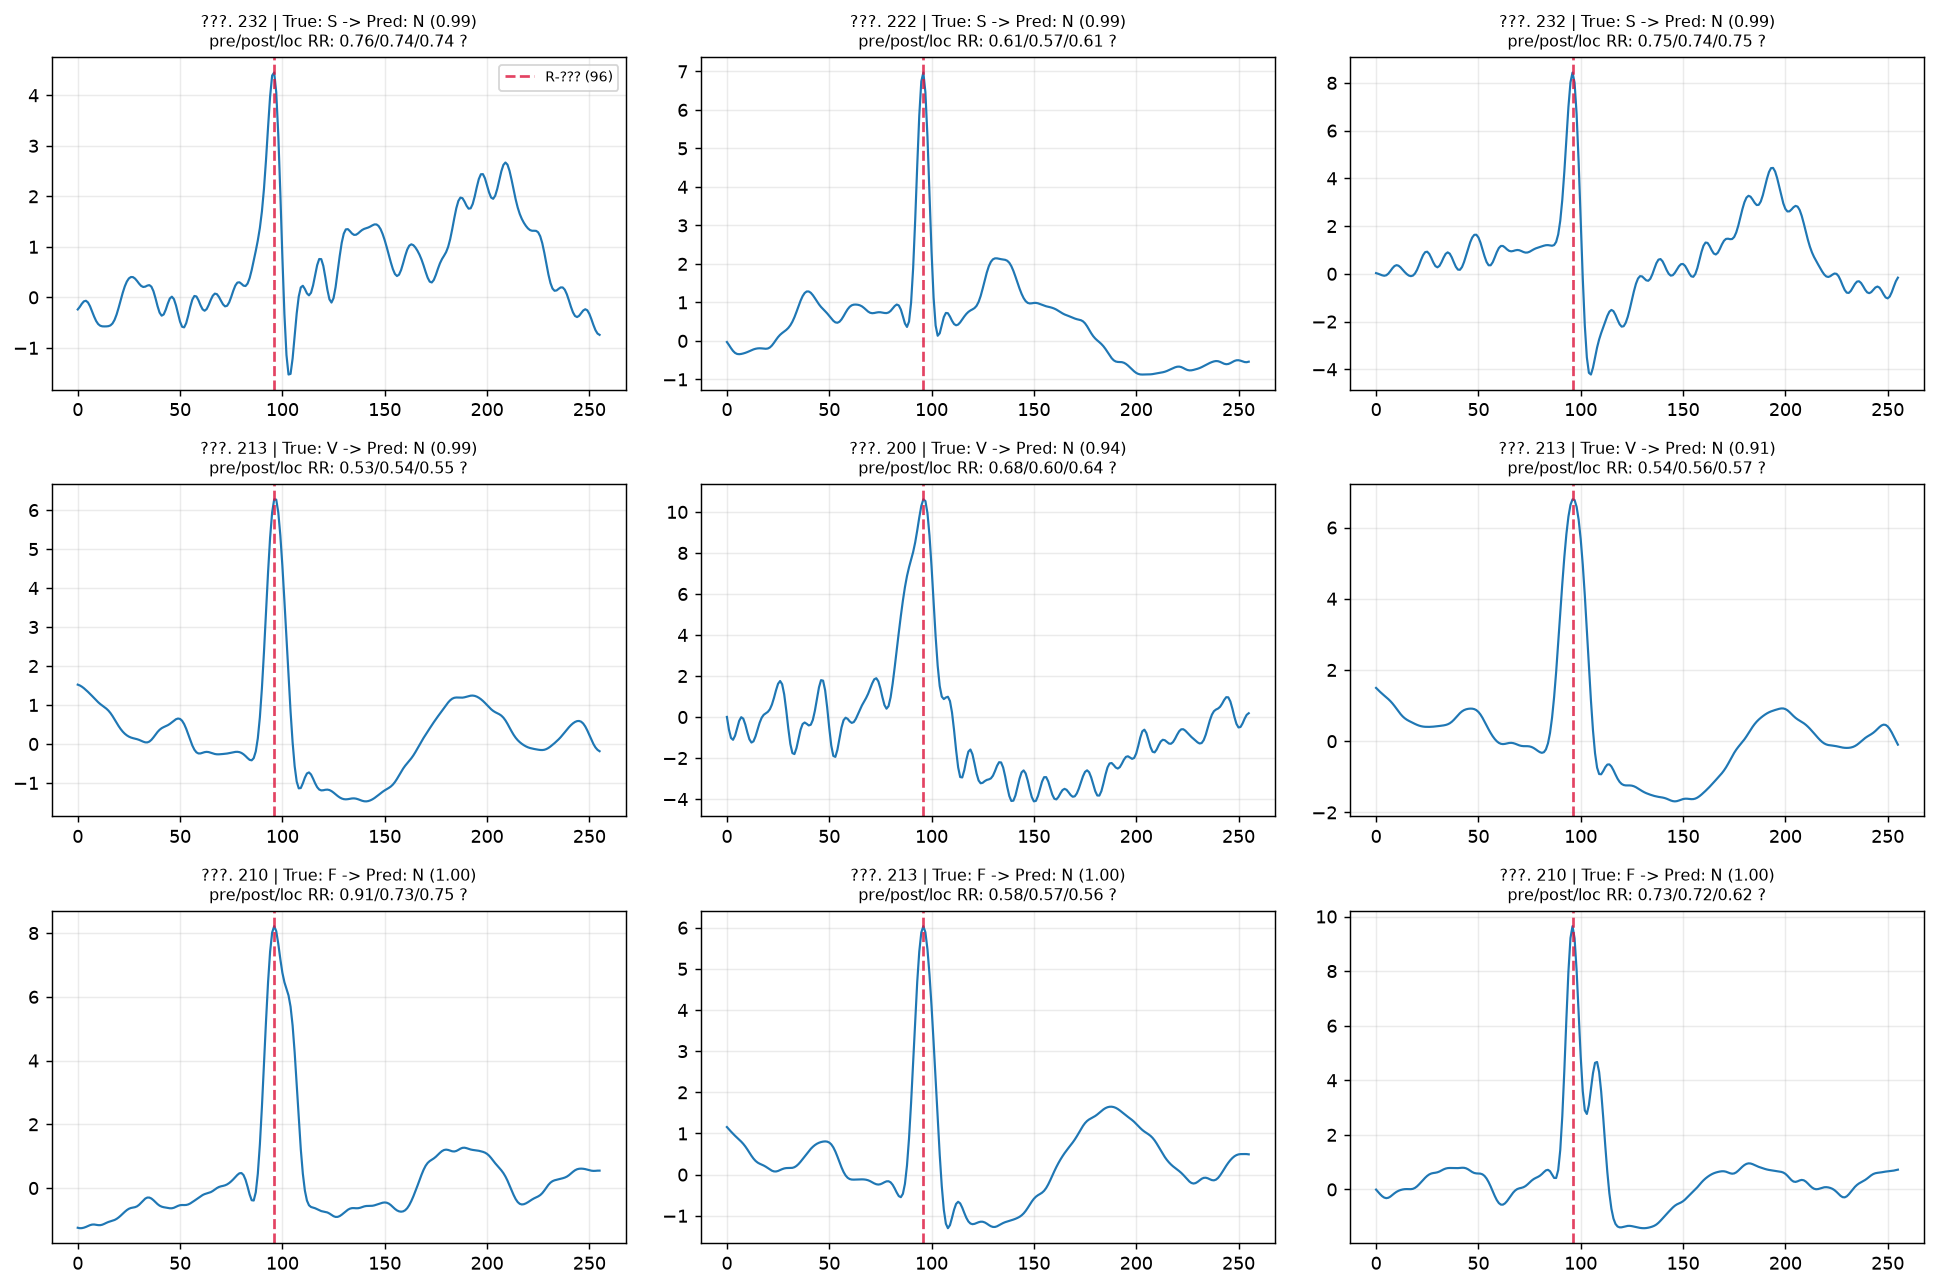

In [3]:
# ???????????? ???????? ????????? ?????? ?? ?????? ??????? (S, V, F)
fig, axes = plt.subplots(3, 3, figsize=(15, 10), dpi=130)
target_classes = [1, 2, 3]  # S, V, F

for row_idx, cls_id in enumerate(target_classes):
    cls_name = IDX_TO_LABEL[cls_id]
    err_indices = np.where((y_true == cls_id) & (y_pred != cls_id))[0]
    # ????????? ?? ??????????? ?????? ? ????????? ????????????
    if len(err_indices) > 0:
        err_conf = np.max(y_probs[err_indices], axis=1)
        top_err = err_indices[np.argsort(-err_conf)[:3]]
    else:
        top_err = []

    for col_idx in range(3):
        ax = axes[row_idx, col_idx]
        if col_idx < len(top_err):
            idx = top_err[col_idx]
            sig = signals[idx, 0] if signals.ndim == 3 else signals[idx]
            pred_cls = IDX_TO_LABEL[int(y_pred[idx])]
            conf = float(y_probs[idx, int(y_pred[idx])])
            pre_rr, post_rr, local_rr = rr_features[idx, 0], rr_features[idx, 1], rr_features[idx, 2]

            ax.plot(sig, color="#1f77b4", linewidth=1.2)
            ax.axvline(r_peak_idx, color="crimson", linestyle="--", alpha=0.8, label=f"R-??? ({r_peak_idx})")
            ax.set_title(
                f"???. {patient_ids[idx]} | True: {cls_name} -> Pred: {pred_cls} ({conf:.2f})\n"
                f"pre/post/loc RR: {pre_rr:.2f}/{post_rr:.2f}/{local_rr:.2f} ?",
                fontsize=9,
            )
            ax.grid(True, alpha=0.25)
            if row_idx == 0 and col_idx == 0:
                ax.legend(loc="upper right", fontsize=8)
        else:
            ax.axis("off")

plt.tight_layout()
plt.show()
